In [4]:

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"

# Check both possible locations for the downloaded dataset
possible_paths = [
    DATA_DIR / "raw" / "ml-latest-small",
    DATA_DIR / "ml-latest-small",
]

DATASET_DIR = next(
    (path for path in possible_paths if (path / "ratings.csv").exists()),
    None
)

if DATASET_DIR is None:
    raise FileNotFoundError(
        "MovieLens dataset not found. "
        "Check the location of ratings.csv."
    )

RATINGS_PATH = DATASET_DIR / "ratings.csv"
MOVIES_PATH = DATASET_DIR / "movies.csv"
TAGS_PATH = DATASET_DIR / "tags.csv"
LINKS_PATH = DATASET_DIR / "links.csv"

print("Project Root:", PROJECT_ROOT)
print("Dataset Directory:", DATASET_DIR)
print("Ratings File:", RATINGS_PATH)
print("Movies File:", MOVIES_PATH)

assert RATINGS_PATH.exists()
assert MOVIES_PATH.exists()


Project Root: c:\Users\yatha\Desktop\personalized-recommendation-engine
Dataset Directory: c:\Users\yatha\Desktop\personalized-recommendation-engine\data\ml-latest-small
Ratings File: c:\Users\yatha\Desktop\personalized-recommendation-engine\data\ml-latest-small\ratings.csv
Movies File: c:\Users\yatha\Desktop\personalized-recommendation-engine\data\ml-latest-small\movies.csv


Load the ratings and movies

In [5]:

import pandas as pd
import numpy as np

ratings = pd.read_csv(RATINGS_PATH)
movies = pd.read_csv(MOVIES_PATH)

print("Ratings Shape:", ratings.shape)
print("Movies Shape:", movies.shape)

display(ratings.head())
display(movies.head())


Ratings Shape: (100836, 4)
Movies Shape: (9742, 3)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


Verify dataset size

In [6]:

print("Total Ratings:", len(ratings))
print("Unique Users:", ratings["userId"].nunique())
print("Unique Movies Rated:", ratings["movieId"].nunique())
print("Total Movies in Metadata:", len(movies))

print("\nRating Range:")
print("Minimum:", ratings["rating"].min())
print("Maximum:", ratings["rating"].max())

assert ratings["rating"].between(0.5, 5.0).all()

print("\nDataset loaded successfully!")


Total Ratings: 100836
Unique Users: 610
Unique Movies Rated: 9724
Total Movies in Metadata: 9742

Rating Range:
Minimum: 0.5
Maximum: 5.0

Dataset loaded successfully!


Check missing values

In [7]:

print("Missing Values in Ratings:")
display(ratings.isnull().sum())

print("\nMissing Values in Movies:")
display(movies.isnull().sum())


Missing Values in Ratings:


userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


Missing Values in Movies:


movieId    0
title      0
genres     0
dtype: int64

Check duplicate records

In [8]:

print("Duplicate rating rows:", ratings.duplicated().sum())

print(
    "Duplicate user-movie pairs:",
    ratings.duplicated(subset=["userId", "movieId"]).sum()
)

print("Duplicate movie rows:", movies.duplicated().sum())

print("Duplicate movie IDs:", movies["movieId"].duplicated().sum())


Duplicate rating rows: 0
Duplicate user-movie pairs: 0
Duplicate movie rows: 0
Duplicate movie IDs: 0


Rating distribution

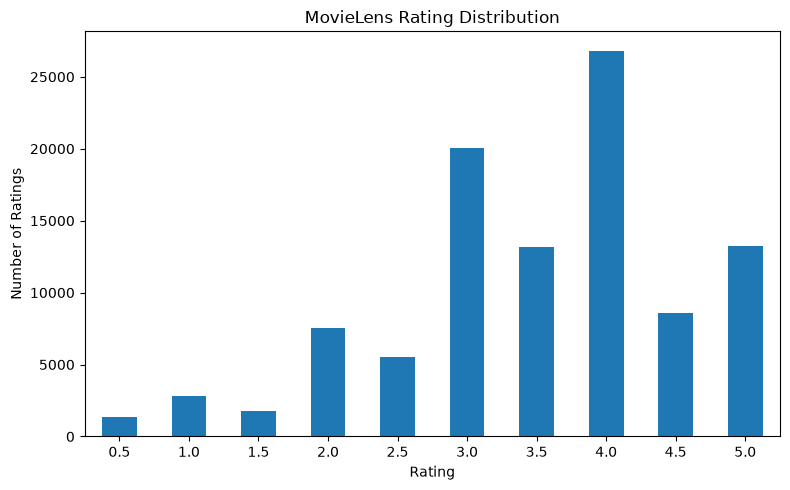

rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64

In [9]:

import matplotlib.pyplot as plt

rating_counts = ratings["rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
rating_counts.plot(kind="bar")

plt.title("MovieLens Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

display(rating_counts)


User activity analysis

Total Users: 610
Average Ratings per User: 165.30491803278687
Median Ratings per User: 70.5
Minimum Ratings per User: 20
Maximum Ratings per User: 2698


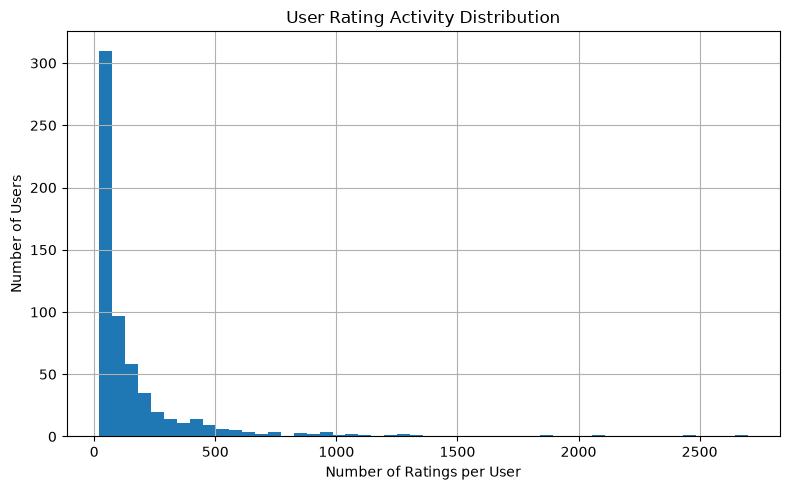

In [10]:

user_activity = ratings.groupby("userId").size()

print("Total Users:", ratings["userId"].nunique())
print("Average Ratings per User:", user_activity.mean())
print("Median Ratings per User:", user_activity.median())
print("Minimum Ratings per User:", user_activity.min())
print("Maximum Ratings per User:", user_activity.max())

plt.figure(figsize=(8, 5))
user_activity.hist(bins=50)

plt.title("User Rating Activity Distribution")
plt.xlabel("Number of Ratings per User")
plt.ylabel("Number of Users")

plt.tight_layout()
plt.show()


Most popular movies

In [11]:

movie_activity = (
    ratings.groupby("movieId")
    .agg(
        rating_count=("rating", "count"),
        average_rating=("rating", "mean")
    )
    .reset_index()
)

movie_activity = movie_activity.merge(
    movies[["movieId", "title"]],
    on="movieId",
    how="left"
)

movie_activity = movie_activity.sort_values(
    "rating_count",
    ascending=False
)

display(movie_activity.head(20))


,movieId,rating_count,average_rating,title
314,356,329,4.164134,Forrest Gump (1994)
277,318,317,4.429022,"Shawshank Redemption, The (1994)"
257,296,307,4.197068,Pulp Fiction (1994)
510,593,279,4.161290,"Silence of the Lambs, The (1991)"
1938,2571,278,4.192446,"Matrix, The (1999)"
224,260,251,4.231076,Star Wars: Episode IV - A New Hope (1977)
418,480,238,3.750000,Jurassic Park (1993)
97,110,237,4.031646,Braveheart (1995)
507,589,224,3.970982,Terminator 2: Judgment Day (1991)
461,527,220,4.225000,Schindler's List (1993)


Genre analysis

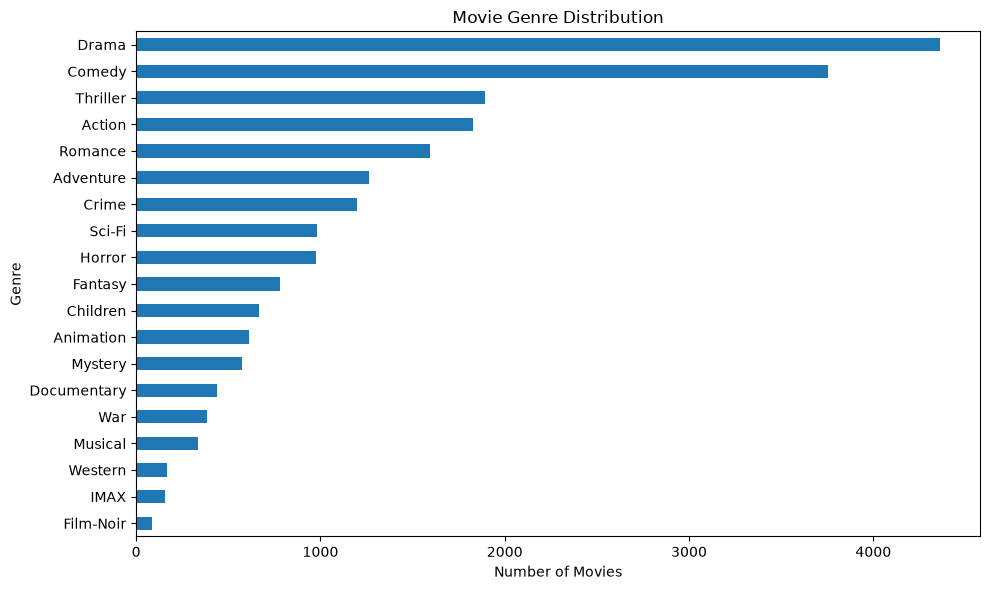

genres
Drama          4361
Comedy         3756
Thriller       1894
Action         1828
Romance        1596
Adventure      1263
Crime          1199
Sci-Fi          980
Horror          978
Fantasy         779
Children        664
Animation       611
Mystery         573
Documentary     440
War             382
Musical         334
Western         167
IMAX            158
Film-Noir        87
Name: count, dtype: int64

In [12]:

genre_counts = (
    movies["genres"]
    .str.split("|")
    .explode()
    .value_counts()
)

genre_counts = genre_counts.drop(
    labels=["(no genres listed)"],
    errors="ignore"
)

plt.figure(figsize=(10, 6))
genre_counts.sort_values().plot(kind="barh")

plt.title("Movie Genre Distribution")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

display(genre_counts)


Timestamp analysis

Earliest Rating: 1996-03-29 18:36:55+00:00
Latest Rating: 2018-09-24 14:27:30+00:00


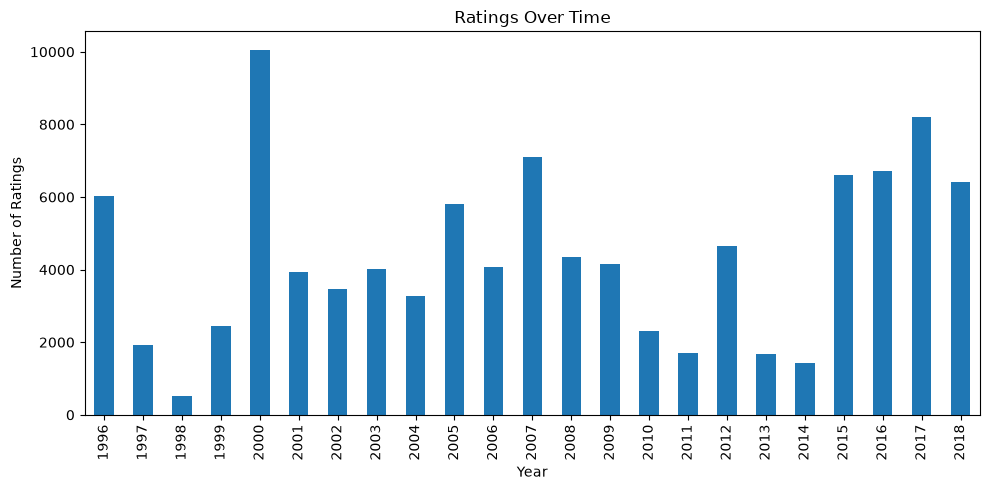

In [13]:

ratings["timestamp"] = pd.to_datetime(
    ratings["timestamp"],
    unit="s",
    utc=True
)

print("Earliest Rating:", ratings["timestamp"].min())
print("Latest Rating:", ratings["timestamp"].max())

ratings["rating_year"] = ratings["timestamp"].dt.year

yearly_ratings = ratings["rating_year"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
yearly_ratings.plot(kind="bar")

plt.title("Ratings Over Time")
plt.xlabel("Year")
plt.ylabel("Number of Ratings")

plt.tight_layout()
plt.show()


Save dataset statistics

In [14]:

from pathlib import Path

REPORTS_DIR = PROJECT_ROOT / "runs" / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

dataset_stats = {
    "total_ratings": len(ratings),
    "total_users": ratings["userId"].nunique(),
    "unique_rated_movies": ratings["movieId"].nunique(),
    "total_movies": len(movies),
    "average_rating": ratings["rating"].mean(),
    "minimum_rating": ratings["rating"].min(),
    "maximum_rating": ratings["rating"].max(),
    "missing_ratings": ratings.isnull().sum().sum(),
    "missing_movies": movies.isnull().sum().sum(),
    "duplicate_rating_rows": ratings.duplicated().sum(),
    "duplicate_user_movie_pairs": ratings.duplicated(
        subset=["userId", "movieId"]
    ).sum(),
    "earliest_rating": str(ratings["timestamp"].min()),
    "latest_rating": str(ratings["timestamp"].max()),
}

stats_df = pd.DataFrame(
    list(dataset_stats.items()),
    columns=["Metric", "Value"]
)

display(stats_df)

stats_df.to_csv(
    REPORTS_DIR / "dataset_statistics.csv",
    index=False
)

print("Dataset statistics saved successfully.")


,Metric,Value
0,total_ratings,100836
1,total_users,610
2,unique_rated_movies,9724
3,total_movies,9742
4,average_rating,3.501557
5,minimum_rating,0.5
6,maximum_rating,5.0
7,missing_ratings,0
8,missing_movies,0
9,duplicate_rating_rows,0


Dataset statistics saved successfully.


Final verification

In [15]:

assert not ratings.empty
assert not movies.empty

assert ratings["rating"].between(0.5, 5.0).all()
assert ratings["timestamp"].notna().all()

assert "userId" in ratings.columns
assert "movieId" in ratings.columns
assert "rating" in ratings.columns

assert "title" in movies.columns
assert "genres" in movies.columns

print("Notebook 01 completed successfully!")
print("Ratings Shape:", ratings.shape)
print("Movies Shape:", movies.shape)
print("Statistics:", REPORTS_DIR / "dataset_statistics.csv")


Notebook 01 completed successfully!
Ratings Shape: (100836, 5)
Movies Shape: (9742, 3)
Statistics: c:\Users\yatha\Desktop\personalized-recommendation-engine\runs\reports\dataset_statistics.csv
